# Chapter 4: Exploring Categories

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 4.1 Counting Labels

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('book.mplstyle')

customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
cancels = pd.read_csv('cancellations.csv',
                      parse_dates=['cancel_date'])
tickets = pd.read_csv('support_tickets.csv',
                      parse_dates=['opened_date'])
customers[['city', 'region', 'age', 'channel', 'plan']].head()

,city,region,age,channel,plan
0,Houston,South,45.0,Podcast,Basic
1,Nashville,South,30.0,Email,Basic
2,Los Angeles,West,40.0,Email,Standard
3,Denver,West,39.0,Search,Basic
4,Chicago,Midwest,28.0,Search,Basic


In [2]:
customers[['city', 'region', 'channel', 'plan', 'device']].nunique()

city       20
region      4
channel     5
plan        3
device      2
dtype: int64

### `s.value_counts()`

In [3]:
customers['channel'].value_counts()

channel
Search      1472
Social      1067
Podcast      678
Referral     548
Email        445
Name: count, dtype: int64

### Shares with `normalize=True`

In [4]:
customers['channel'].value_counts(normalize=True).round(3)

channel
Search      0.350
Social      0.253
Podcast     0.161
Referral    0.130
Email       0.106
Name: proportion, dtype: float64

In [5]:
plan_counts = customers['plan'].value_counts()
plan_shares = customers['plan'].value_counts(normalize=True)
pd.DataFrame({'customers': plan_counts,
              'percent': (plan_shares * 100).round(1)})

,customers,percent
plan,,
Basic,1887,44.8
Standard,1511,35.9
Premium,812,19.3


### Sorting the result

In [6]:
plan_order = ['Basic', 'Standard', 'Premium']
customers['plan'].value_counts().loc[plan_order]

plan
Basic       1887
Standard    1511
Premium      812
Name: count, dtype: int64

## 4.2 Blanks Are a Category Too

In [7]:
customers['age'].value_counts().head(3)

age
18.0    171
39.0    166
36.0    152
Name: count, dtype: int64

In [8]:
customers['age'].value_counts(dropna=False).head(3)

age
18.0    171
NaN     167
39.0    166
Name: count, dtype: int64

In [9]:
no_age = customers[customers['age'].isna()]
no_age['channel'].value_counts(normalize=True).round(3)

channel
Social      0.611
Search      0.174
Email       0.102
Podcast     0.060
Referral    0.054
Name: proportion, dtype: float64

## 4.3 Rare Categories

In [10]:
city_shares = customers['city'].value_counts(normalize=True)
city_shares.round(3)

city
New York        0.129
Los Angeles     0.082
Chicago         0.073
Houston         0.070
Dallas          0.059
Phoenix         0.054
Philadelphia    0.050
Seattle         0.049
Atlanta         0.047
Boston          0.046
San Diego       0.044
Denver          0.042
Miami           0.038
Columbus        0.035
Portland        0.034
Minneapolis     0.033
Detroit         0.033
Charlotte       0.032
Nashville       0.028
Pittsburgh      0.023
Name: proportion, dtype: float64

In [11]:
rare_cities = city_shares[city_shares < 0.03]
print(f'Rare cities: {len(rare_cities)}')
print(f'Their combined share: {rare_cities.sum():.1%}')

Rare cities: 2
Their combined share: 5.1%


### Grouping with `where()` and `isin()`

In [12]:
big_cities = city_shares[city_shares >= 0.03].index
city_grouped = customers['city'].where(
    customers['city'].isin(big_cities), 'Other')
city_grouped.value_counts()

city
New York        543
Los Angeles     345
Chicago         306
Houston         295
Dallas          249
Phoenix         226
Other           213
Philadelphia    210
Seattle         207
Atlanta         199
Boston          193
San Diego       185
Denver          176
Miami           159
Columbus        147
Portland        142
Minneapolis     141
Detroit         139
Charlotte       135
Name: count, dtype: int64

In [13]:
customers['city_group'] = city_grouped
customers['city_group'].nunique()

19

### `s.replace()`

In [14]:
tickets['topic'].value_counts(normalize=True).round(3)

topic
Late delivery      0.443
Billing            0.181
Product quality    0.155
Change address     0.111
Other              0.109
Name: proportion, dtype: float64

In [15]:
topic_grouped = tickets['topic'].replace(
    {'Change address': 'Other'})
topic_grouped.value_counts()

topic
Late delivery      612
Other              304
Billing            250
Product quality    214
Name: count, dtype: int64

## 4.4 Charting Categories

### `sns.countplot()`

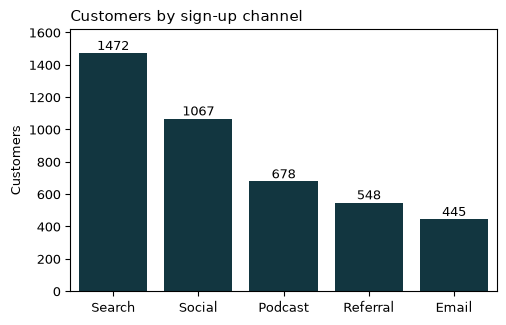

In [16]:
channel_order = customers['channel'].value_counts().index

ax = sns.countplot(data=customers, x='channel', order=channel_order,
                   color='#0b3a47')
ax.bar_label(ax.containers[0])
ax.margins(y=0.1)
ax.set_title('Customers by sign-up channel')
ax.set_xlabel('')
ax.set_ylabel('Customers')
plt.show()

### Horizontal bars for long labels

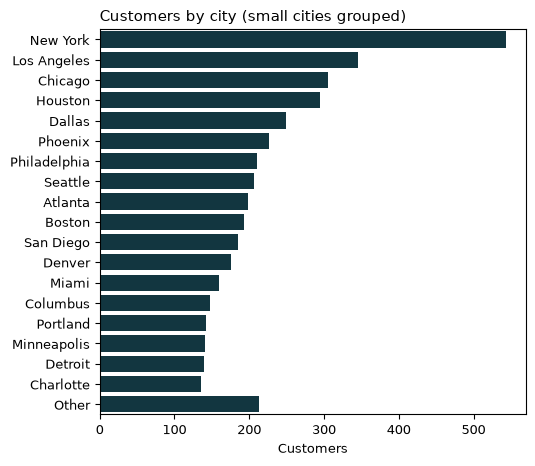

In [17]:
named = list(big_cities)
city_order = named + ['Other']

fig, ax = plt.subplots(figsize=(5.5, 5))
sns.countplot(data=customers, y='city_group', order=city_order,
              color='#0b3a47', ax=ax)
ax.set_title('Customers by city (small cities grouped)')
ax.set_xlabel('Customers')
ax.set_ylabel('')
plt.show()

### Splitting bars with `hue=`

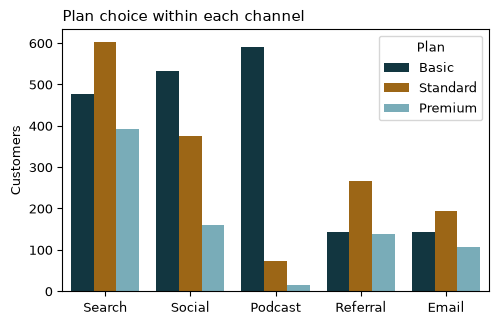

In [18]:
ax = sns.countplot(data=customers, x='channel', order=channel_order,
                   hue='plan', hue_order=plan_order,
                   palette=['#0b3a47', '#b26a00', '#6fb3c2'])
ax.set_title('Plan choice within each channel')
ax.set_xlabel('')
ax.set_ylabel('Customers')
ax.legend(title='Plan')
plt.show()

## 4.5 The 80/20 Check

### `s.cumsum()`

In [19]:
reason_shares = cancels['reason'].value_counts(normalize=True)
reason_shares.cumsum().round(3)

reason
Too expensive        0.273
Too much coffee      0.480
Other                0.670
Taste                0.850
Delivery problems    1.000
Name: proportion, dtype: float64

### Total spend per customer

In [20]:
spend = (orders.groupby('customer_id')['amount'].sum()
         .sort_values(ascending=False))
spend.head()

customer_id
2010    1527.18
1157    1427.88
1052    1355.09
1051    1304.72
1280    1282.63
Name: amount, dtype: float64

In [21]:
print(f'Customers with orders: {len(spend)}')
print(f'Customers in the table: {len(customers)}')
print(f'Median customer spend: ${spend.median():.2f}')
print(f'Mean customer spend: ${spend.mean():.2f}')

Customers with orders: 4210
Customers in the table: 4210
Median customer spend: $95.36
Mean customer spend: $184.10


### The share of revenue from the top 20%

In [22]:
spend_share = spend / spend.sum()
cum_share = spend_share.cumsum()
cum_share.head()

customer_id
2010    0.001970
1157    0.003813
1052    0.005561
1051    0.007244
1280    0.008899
Name: amount, dtype: float64

In [23]:
top_n = round(len(spend) * 0.2)
top_share = cum_share.iloc[top_n - 1]
print(f'Top 20% of customers: {top_n}')
print(f'Their share of revenue: {top_share:.1%}')

Top 20% of customers: 842
Their share of revenue: 61.1%


In [24]:
bottom_share = spend.iloc[-top_n:].sum() / spend.sum()
print(f'Bottom 20% of customers: {bottom_share:.1%} of revenue')

Bottom 20% of customers: 1.3% of revenue


In [25]:
half = (cum_share < 0.5).sum() + 1
print(f'Customers needed for half of revenue: {half}')
print(f'That is {half / len(spend):.1%} of all customers')

Customers needed for half of revenue: 598
That is 14.2% of all customers


### The cumulative chart

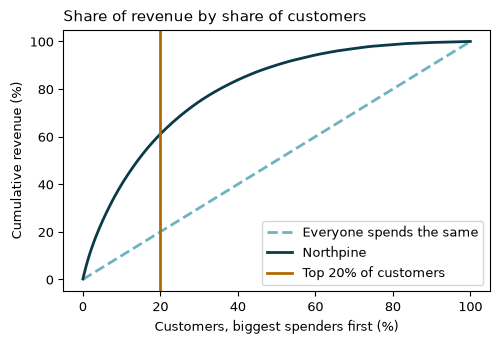

In [26]:
n = len(spend)
customer_pct = np.arange(1, n + 1) / n * 100

fig, ax = plt.subplots()
ax.plot([0, 100], [0, 100], color='#6fb3c2', linestyle='--',
        label='Everyone spends the same')
ax.plot(customer_pct, cum_share.values * 100, color='#0b3a47',
        label='Northpine')
ax.axvline(20, color='#b26a00', label='Top 20% of customers')
ax.set_title('Share of revenue by share of customers')
ax.set_xlabel('Customers, biggest spenders first (%)')
ax.set_ylabel('Cumulative revenue (%)')
ax.legend()
plt.show()

### Who are the top customers?

In [27]:
top_ids = spend.index[:top_n]
by_id = customers.set_index('customer_id')
top_plans = by_id.loc[top_ids, 'plan'].value_counts(normalize=True)
pd.DataFrame({'top 20%': top_plans.round(3),
              'all customers': plan_shares.round(3)})

,top 20%,all customers
plan,,
Basic,0.068,0.448
Premium,0.476,0.193
Standard,0.456,0.359
